# NB02 - Simulasi Buta Warna Parsial

Notebook ini menjalankan model Machado pada seluruh citra hasil NB01. Setiap citra menghasilkan delapan keluaran: protan dan deutan pada empat nilai severity.

In [1]:
%pip install opencv-python-headless numpy pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [2]:
from __future__ import annotations
import sys, time
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from machado import simulate_machado_bgr
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/01/output/dataset_preparation_report.csv")
MANIFEST_PATH=RESEARCH_ROOT/"notebooks/01/output/dataset_preparation_report.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/02/output"
SIMULATED_DIR=OUTPUT_DIR/"simulated_images"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True); SIMULATED_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)
# SAMPLE_SIZE=250


## Tahap 2 - Memuat dan Memeriksa Manifest Praproses

In [3]:
manifest=pd.read_csv(MANIFEST_PATH).sort_values(["source_class","source_file_name"]).reset_index(drop=True)
required={"subset","source_class","source_file_name","output_file_name","output_path","output_sha256"}
missing=required-set(manifest.columns)
if missing: raise ValueError(f"Kolom manifest tidak lengkap: {sorted(missing)}")
if manifest.empty: raise RuntimeError("Manifest NB01 kosong.")
# if len(manifest) > SAMPLE_SIZE:
#     manifest = manifest.head(SAMPLE_SIZE).copy()
print(f"Citra sumber yang disimulasikan: {len(manifest)}")
print(manifest.groupby("source_class").size().to_string())

Citra sumber yang disimulasikan: 3604
source_class
001apple          398
002orange         424
003pear           263
004tomato         404
005strawberry     441
006banana         372
007watermelon     233
009peach          400
010pomegranate    261
012starfruit      155
014lemon          141
015pomelo         112


## Tahap 3 - Menyusun Delapan Kondisi Simulasi

In [4]:
def severity_folder(severity: float) -> str:
    return f"severity_{int(round(severity * 100)):03d}"

def simulation_output_path(row: pd.Series, cvd_family: str, severity: float) -> Path:
    return SIMULATED_DIR / cvd_family / severity_folder(severity) / row["source_class"] / row["output_file_name"]

jobs=[]
for _, row in manifest.iterrows():
    for cvd_family in CVD_FAMILIES:
        for severity in SEVERITIES:
            jobs.append({"subset":row["subset"],"source_class":row["source_class"],"source_file_name":row["source_file_name"],"input_path":row["output_path"],"input_sha256":row["output_sha256"],"cvd_family":cvd_family,"severity":severity,"output_path":str(simulation_output_path(row,cvd_family,severity))})
print(f"Jumlah pekerjaan: {len(jobs)}")

Jumlah pekerjaan: 28832


## Tahap 4 - Menjalankan Simulasi Machado

In [5]:
report_rows = []
error_rows = []
started = time.perf_counter()

for index, job in enumerate(jobs, start=1):
    try:
        source = cv2.imread(job["input_path"], cv2.IMREAD_COLOR)
        if source is None:
            raise ValueError("Citra masukan tidak dapat dibaca")
            
        target = Path(job["output_path"])
        target.parent.mkdir(parents=True, exist_ok=True)
        
        # Eksekusi fungsi simulasi
        result, diagnostics = simulate_machado_bgr(
            source, job["cvd_family"], float(job["severity"])
        )
        
        if not cv2.imwrite(str(target), result):
            raise IOError("Citra hasil tidak dapat ditulis")
            
        # Hitung metrik yang belum disediakan oleh engine secara langsung
        difference = np.abs(result.astype(np.int16) - source.astype(np.int16))
        mean_abs_rgb_diff = float(difference.mean() / 255.0)
        changed_pixel_prop = float(np.any(result != source, axis=2).mean())
        
        # Petakan key dari engine (clip_*_ratio -> clipping_*_proportion)
        report_rows.append({
            **job,
            "output_sha256": sha256_file(target),
            "mean_absolute_rgb_difference": mean_abs_rgb_diff,
            "changed_pixel_proportion": changed_pixel_prop,
            "clipping_low_proportion": diagnostics["clip_low_ratio"],
            "clipping_high_proportion": diagnostics["clip_high_ratio"],
            "clipping_any_proportion": diagnostics["clip_any_ratio"],
        })
        
    except Exception as error:
        error_rows.append({**job, "error": str(error)})
        
    if index % 1000 == 0 or index == len(jobs):
        print(f"{index}/{len(jobs)} pekerjaan selesai, {time.perf_counter()-started:.1f} detik")

# Handling aman jika seluruh proses gagal
if not report_rows:
    error_frame = pd.DataFrame(error_rows)
    print("\n[ERROR] Sampel kesalahan yang terjadi selama simulasi:")
    print(error_frame[["cvd_family", "severity", "error"]].head().to_string(index=False))
    raise RuntimeError("Semua simulasi gagal. Periksa log error di atas.")

# Pengurutan dilakukan setelah memastikan report_rows tidak kosong
report = (
    pd.DataFrame(report_rows)
    .sort_values(["cvd_family", "severity", "source_class", "source_file_name"])
    .reset_index(drop=True)
)

print(f"Simulasi berhasil: {len(report)} | gagal: {len(error_rows)}")

1000/28832 pekerjaan selesai, 103.9 detik
2000/28832 pekerjaan selesai, 190.9 detik
3000/28832 pekerjaan selesai, 273.4 detik
4000/28832 pekerjaan selesai, 367.0 detik
5000/28832 pekerjaan selesai, 447.6 detik
6000/28832 pekerjaan selesai, 528.4 detik
7000/28832 pekerjaan selesai, 608.6 detik
8000/28832 pekerjaan selesai, 684.2 detik
9000/28832 pekerjaan selesai, 763.3 detik
10000/28832 pekerjaan selesai, 843.1 detik
11000/28832 pekerjaan selesai, 928.0 detik
12000/28832 pekerjaan selesai, 1008.7 detik
13000/28832 pekerjaan selesai, 1089.2 detik
14000/28832 pekerjaan selesai, 1168.5 detik
15000/28832 pekerjaan selesai, 1249.1 detik
16000/28832 pekerjaan selesai, 1329.1 detik
17000/28832 pekerjaan selesai, 1408.0 detik
18000/28832 pekerjaan selesai, 1487.2 detik
19000/28832 pekerjaan selesai, 1566.8 detik
20000/28832 pekerjaan selesai, 1646.6 detik
21000/28832 pekerjaan selesai, 1725.3 detik
22000/28832 pekerjaan selesai, 1802.6 detik
23000/28832 pekerjaan selesai, 1879.2 detik
24000/28

## Tahap 5 - Verifikasi Struktur Keluaran

In [6]:
verification=[]
for _, row in report.iterrows():
    image=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    verification.append({"output_path":row["output_path"],"readable":image is not None,"width":None if image is None else int(image.shape[1]),"height":None if image is None else int(image.shape[0])})
verification=pd.DataFrame(verification)
if not verification["readable"].all(): raise RuntimeError("Ada citra simulasi yang tidak dapat dibaca.")
print(f"Seluruh {len(verification)} keluaran simulasi dapat dibaca.")

Seluruh 28832 keluaran simulasi dapat dibaca.


## Tahap 6 - Visualisasi Perubahan Severity

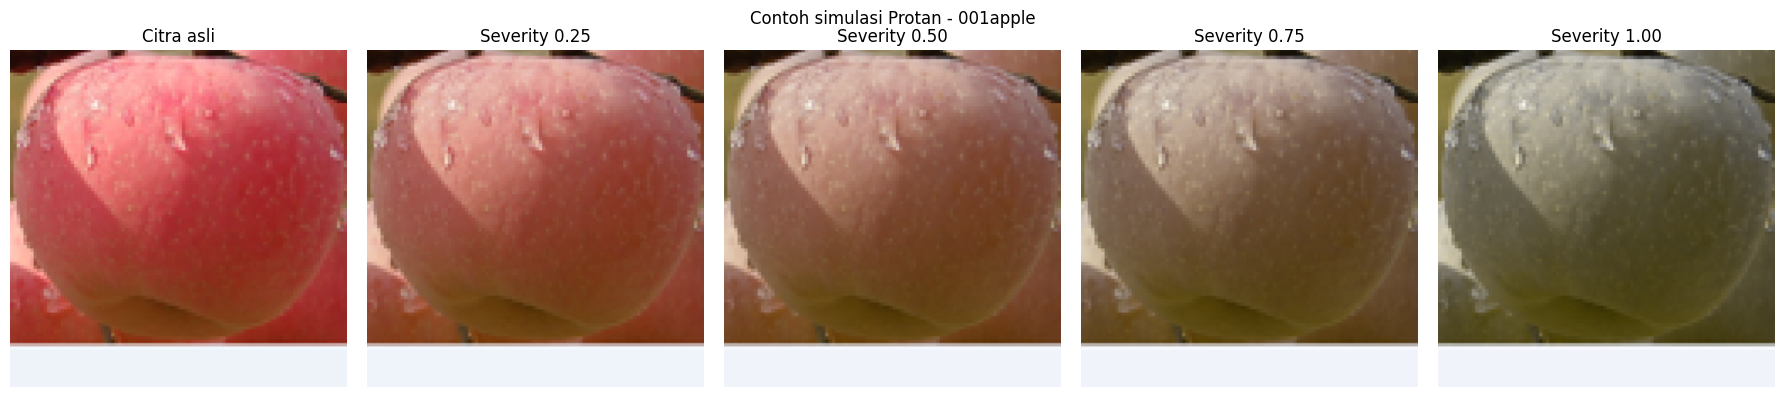

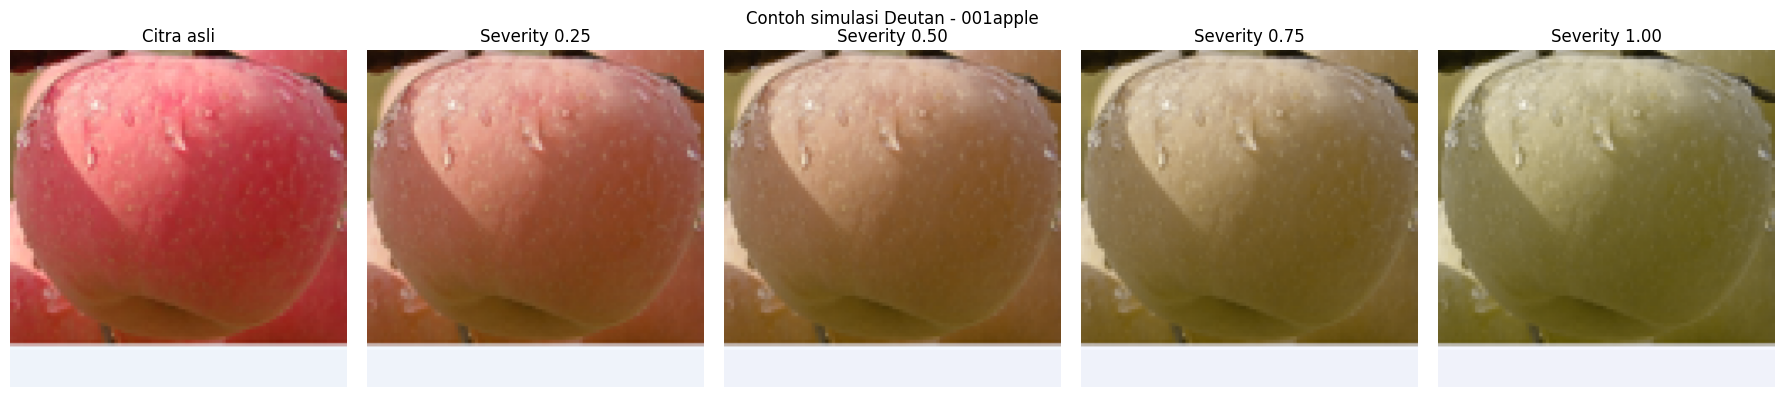

In [7]:
representative=manifest.iloc[0]
for cvd_family in CVD_FAMILIES:
    fig, axes=plt.subplots(1,5,figsize=(18,4))
    original=cv2.cvtColor(cv2.imread(representative["output_path"]),cv2.COLOR_BGR2RGB)
    axes[0].imshow(original); axes[0].set_title("Citra asli"); axes[0].axis("off")
    for axis,severity in zip(axes[1:],SEVERITIES):
        result=cv2.cvtColor(cv2.imread(str(simulation_output_path(representative,cvd_family,severity))),cv2.COLOR_BGR2RGB)
        axis.imshow(result); axis.set_title(f"Severity {severity:.2f}"); axis.axis("off")
    fig.suptitle(f"Contoh simulasi {cvd_family.title()} - {representative['source_class']}")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/f"simulation_severity_{cvd_family}.png",dpi=180,bbox_inches="tight"); plt.show()

## Tahap 7 - Ekspor Ringkasan Simulasi

In [8]:
group_summary = report.groupby(["cvd_family", "severity"], as_index=False).agg(
    image_count=("output_path", "size"),
    mean_absolute_rgb_difference=("mean_absolute_rgb_difference", "mean"),
    changed_pixel_proportion=("changed_pixel_proportion", "mean"),
    clipping_any_proportion=("clipping_any_proportion", "mean")
)

# 1. Simpan laporan simulasi utama
write_csv(report, OUTPUT_DIR / "simulation_report.csv", ["subset", "source_class", "source_file_name", "cvd_family", "severity"])

# 2. Simpan laporan error (dengan proteksi jika error_rows kosong)
error_cols = ["subset", "source_class", "source_file_name", "cvd_family", "severity", "error"]
df_errors = pd.DataFrame(error_rows) if error_rows else pd.DataFrame(columns=error_cols)
write_csv(df_errors, OUTPUT_DIR / "simulation_errors.csv", ["source_class", "source_file_name", "cvd_family", "severity"], allow_empty=True)

# 3. Simpan verifikasi dan ringkasan kelompok
write_csv(verification, OUTPUT_DIR / "simulation_verification.csv", ["output_path"])
write_csv(group_summary, OUTPUT_DIR / "simulation_group_summary.csv", ["cvd_family", "severity"])

# 4. Simpan summary JSON
write_json({
    "source_image_count": len(manifest),
    "condition_count": 8,
    "expected_simulation_count": len(jobs),
    "successful_simulation_count": len(report),
    "error_count": len(error_rows),
    "cvd_families": list(CVD_FAMILIES),
    "severities": list(SEVERITIES)
}, OUTPUT_DIR / "simulation_summary.json")

group_summary

,cvd_family,severity,image_count,mean_absolute_rgb_difference,changed_pixel_proportion,clipping_any_proportion
0,deutan,0.25,3604,0.028954,0.884828,0.169573
1,deutan,0.50,3604,0.045829,0.925980,0.182436
2,deutan,0.75,3604,0.057087,0.935412,0.153656
3,deutan,1.00,3604,0.065540,0.942634,0.181115
4,protan,0.25,3604,0.026716,0.923941,0.208389
5,protan,0.50,3604,0.044455,0.941792,0.238748
6,protan,0.75,3604,0.058025,0.944811,0.223763
7,protan,1.00,3604,0.070034,0.945449,0.261250
